In [ ]:
  !pip install -q kaggle

In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"himanshuthakare18","key":"d8cdb28c0e49384e7c26797d7d1e9271"}'}

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!ls -l /content


total 8
-rw-r--r-- 1 root root   73 Jan 12 08:05 kaggle.json
drwxr-xr-x 1 root root 4096 Dec  9 14:42 sample_data


In [ ]:
import os

# Create .kaggle directory if it doesn't exist
!mkdir -p ~/.kaggle

# Move kaggle (3).json to the correct location and rename it to kaggle.json
!cp '/content/kaggle.json' ~/.kaggle/kaggle.json

# Set appropriate permissions
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
# Download the dataset
!kaggle datasets download -d abdelghaniaaba/wildfire-prediction-dataset

Dataset URL: https://www.kaggle.com/datasets/abdelghaniaaba/wildfire-prediction-dataset
License(s): other
 96% 1.39G/1.45G [00:23<00:00, 169MB/s]
100% 1.45G/1.45G [00:23<00:00, 66.2MB/s]


In [ ]:
!unzip wildfire-prediction-dataset.zip -d wild_data

Streaming output truncated to the last 5000 lines.
  inflating: wild_data/valid/nowildfire/-73.465183,45.443641.jpg  
  inflating: wild_data/valid/nowildfire/-73.465388,45.584881.jpg  
  inflating: wild_data/valid/nowildfire/-73.469451,45.480331.jpg  
  inflating: wild_data/valid/nowildfire/-73.471252,45.51974.jpg  
  inflating: wild_data/valid/nowildfire/-73.472693,45.427766.jpg  
  inflating: wild_data/valid/nowildfire/-73.473015,45.435254.jpg  
  inflating: wild_data/valid/nowildfire/-73.475051,45.56612.jpg  
  inflating: wild_data/valid/nowildfire/-73.477079,45.597274.jpg  
  inflating: wild_data/valid/nowildfire/-73.478813,45.555686.jpg  
  inflating: wild_data/valid/nowildfire/-73.479478,45.524618.jpg  
  inflating: wild_data/valid/nowildfire/-73.480135,45.528248.jpg  
  inflating: wild_data/valid/nowildfire/-73.480722,45.518864.jpg  
  inflating: wild_data/valid/nowildfire/-73.481149,45.563113.jpg  
  inflating: wild_data/valid/nowildfire/-73.481422,45.559789.jpg  
  inflating: 

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D,Dense, Dropout, Flatten, MaxPooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix
from PIL import ImageFile

In [ ]:
ImageFile.LOAD_TRUNCATED_IMAGES=True

In [ ]:
train_dir='/content/wild_data/train'
test_dir='/content/wild_data/test'

In [ ]:
train_datagen=ImageDataGenerator(rescale=1./255)
test_datagen=ImageDataGenerator(rescale=1./255)

In [ ]:
train_generator=train_datagen.flow_from_directory(
    train_dir,
    target_size=(150,150),
    batch_size=32,
    class_mode='binary')

Found 30250 images belonging to 2 classes.


In [ ]:
model=Sequential(
    [
        Conv2D(32,(3,3),activation='relu',input_shape=(150,150,3)),
        MaxPooling2D(2,2),
        Conv2D(64,(3,3),activation='relu'),
        MaxPooling2D(2,2),
        Flatten(),
        Dense(512,activation='relu'),
        Dropout(0.5),
        Dense(1,activation='sigmoid')
    ]
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.compile(optimizer=Adam(learning_rate=0.0001),loss='binary_crossentropy',metrics=['accuracy'])

In [ ]:
history=model.fit(train_generator,epochs=10,validation_data=train_generator)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
946/946 ━━━━━━━━━━━━━━━━━━━━ 122s 123ms/step - accuracy: 0.8666 - loss: 0.2984 - val_accuracy: 0.9399 - val_loss: 0.1620
Epoch 2/10
946/946 ━━━━━━━━━━━━━━━━━━━━ 128s 114ms/step - accuracy: 0.9372 - loss: 0.1666 - val_accuracy: 0.9481 - val_loss: 0.1413
Epoch 3/10
946/946 ━━━━━━━━━━━━━━━━━━━━ 138s 146ms/step - accuracy: 0.9422 - loss: 0.1555 - val_accuracy: 0.9279 - val_loss: 0.1812
Epoch 4/10
946/946 ━━━━━━━━━━━━━━━━━━━━ 107s 113ms/step - accuracy: 0.9498 - loss: 0.1357 - val_accuracy: 0.9610 - val_loss: 0.1091
Epoch 5/10
946/946 ━━━━━━━━━━━━━━━━━━━━ 107s 113ms/step - accuracy: 0.9576 - loss: 0.1182 - val_accuracy: 0.9691 - val_loss: 0.0912
Epoch 6/10
946/946 ━━━━━━━━━━━━━━━━━━━━ 109s 115ms/step - accuracy: 0.9618 - loss: 0.1025 - val_accuracy: 0.9714 - val_loss: 0.0846
Epoch 7/10
946/946 ━━━━━━━━━━━━━━━━━━━━ 106s 112ms/step - accuracy: 0.9698 - loss: 0.0856 - val_accuracy: 0.9781 - val_loss: 0.0672
Epoch 8/10
946/946 ━━━━━━━━━━━━━━━━━━━━ 108s 114ms/step - accuracy: 0.9744 -

In [ ]:
loss,accuracy=model.evaluate(train_generator)
print(f"Test Accuracy: {accuracy*100:.2f}%")

946/946 ━━━━━━━━━━━━━━━━━━━━ 84s 89ms/step - accuracy: 0.9764 - loss: 0.0640
Test Accuracy: 97.62%


In [ ]:
predictions=model.predict(train_generator)
y_pred=(predictions>0.5).astype(int)
y_true=train_generator.classes

946/946 ━━━━━━━━━━━━━━━━━━━━ 63s 67ms/step


In [ ]:
print('classification report\n',classification_report(y_true,y_pred))
print('classification_report:\n',confusion_matrix(y_true,y_pred))

classification report
               precision    recall  f1-score   support

           0       0.48      0.50      0.49     14500
           1       0.52      0.51      0.51     15750

    accuracy                           0.50     30250
   macro avg       0.50      0.50      0.50     30250
weighted avg       0.50      0.50      0.50     30250

classification_report:
 [[7239 7261]
 [7778 7972]]


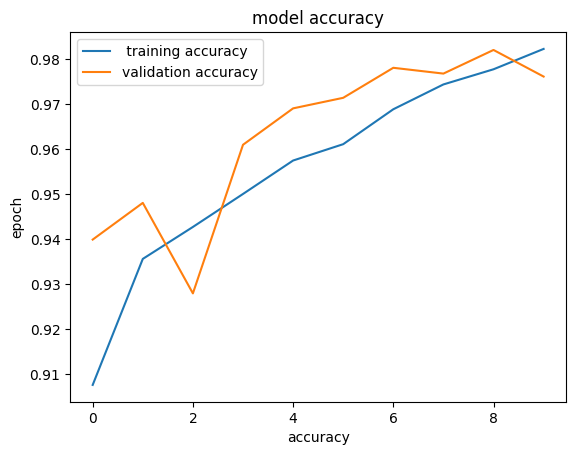

In [ ]:
plt.plot(history.history['accuracy'],label=' training accuracy')
plt.plot(history.history['val_accuracy'],label='validation accuracy')
plt.title('model accuracy')
plt.ylabel('epoch')
plt.xlabel('accuracy')
plt.legend()
plt.show()

In [ ]:
import joblib
joblib.dump(model,'forest_fire_model.pkl')


['forest_fire_model.pkl']

In [ ]:
model.save('forest_fire_model.h5')

In [ ]:
from tensorflow.keras.preprocessing import image

In [ ]:
def predict_and_show_image(image_path):
  img=image.load_img(image_path,target_size=(150,150))
  img_array=image.img_to_array(img)/255.0
  img_array=np.expand_dims(img_array,axis=0)

  plt.imshow(img)
  plt.axis('off')
  plt.show()

  prediction=model.predict(img_array)
  print("Prediction:","Wildfire" if predictions[0]>0.5 else "No wildfire")




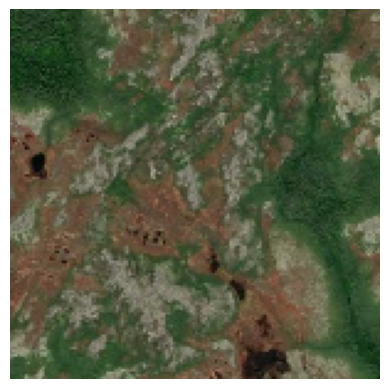

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 875ms/step
Prediction: No wildfire


In [ ]:
predict_and_show_image('/content/wild_data/test/wildfire/-60.73875,50.24761.jpg')

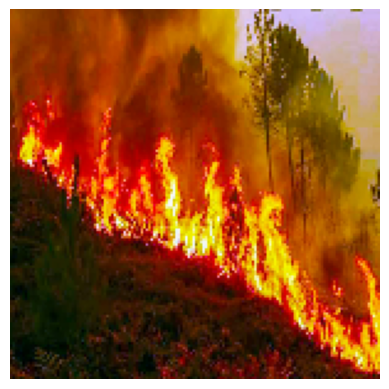

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step
Prediction: No wildfire


In [ ]:
predict_and_show_image('/content/testfire.jpg')